## **BMI500 Lecture 7 Homework**
### ***Question 2: Agent-Based Modeling of Pandemic Spread***

### **Part A. Building the Base Model: Infection Dynamics in a Population** 

#### Import necessary libraries

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

#### Environment and initial conditions

In [15]:
# Simulation parameters
grid_size = 20
n_agents = 200
n_steps = 300
n_runs = 20

# Infection and recovery probabilities
p_values = [0.15, 0.3]
q_values = [0.02, 0.04]

# Agent states: 0 = Susceptible, 1 = Infected, 2 = Recovered
state_names = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']

#### Agentic behaviors

In [16]:
def simulate(p, q, seed=None):
    rng = np.random.default_rng(seed)

    # Random initial positions (x, y) for 200 agents
    positions = rng.integers(0, grid_size, size=(n_agents, 2))

    # Initial states: 195 S, 5 I, 0 R
    states = np.array([0]*195 + [1]*5)

    # Record S, I, R counts over time (including time 0)
    counts = np.zeros((n_steps + 1, 3))
    counts[0] = np.bincount(states, minlength=3)

    # Possible moves: stay, up, down, left, right
    moves = np.array([
        [0, 0],
        [-1, 0],
        [1, 0],
        [0, -1],
        [0, 1]
    ])

    for t in range(1, n_steps + 1):

        # Step 1: Random movement
        random_moves = moves[rng.integers(0, 5, size=n_agents)]
        positions = np.clip(positions + random_moves, 0, grid_size - 1)

        # Step 2: Identify cells containing infected agents
        infected_grid = np.zeros((grid_size, grid_size), dtype=bool)

        infected_positions = positions[states == 1]
        infected_grid[infected_positions[:, 0], infected_positions[:, 1]] = True

        # Step 3: Susceptible agents become infected with probability p
        exposed = infected_grid[positions[:, 0], positions[:, 1]]
        new_infections = (states == 0) & exposed & (rng.random(n_agents) < p)

        # Step 4: Infected agents recover with probability q
        recoveries = (states == 1) & (rng.random(n_agents) < q)

        # Update states simultaneously
        states[new_infections] = 1
        states[recoveries] = 2

        # Step 5: Record counts
        counts[t] = np.bincount(states, minlength=3)

    return counts

#### Simulation (300 time steps)

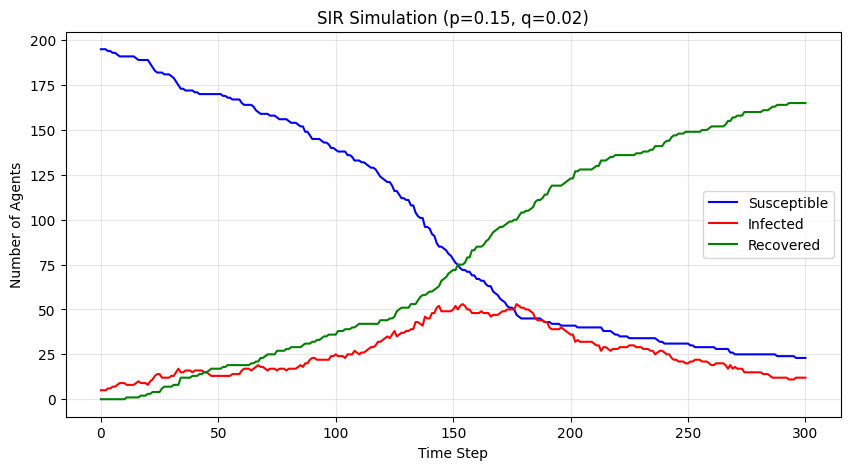

In [17]:
counts = simulate(p=0.15, q=0.02, seed=42)

plt.figure(figsize=(10, 5))

for i in range(3):
    plt.plot(counts[:, i], color=colors[i], label=state_names[i])

plt.xlabel('Time Step')
plt.ylabel('Number of Agents')
plt.title('SIR Simulation (p=0.15, q=0.02)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Sensitivity analysis

In [18]:
results = {}

for p in p_values:
    for q in q_values:

        runs = []

        for run in range(n_runs): # repeat for 20 simulations
            counts = simulate(p, q, seed=run)
            runs.append(counts)

        results[(p, q)] = np.array(runs)

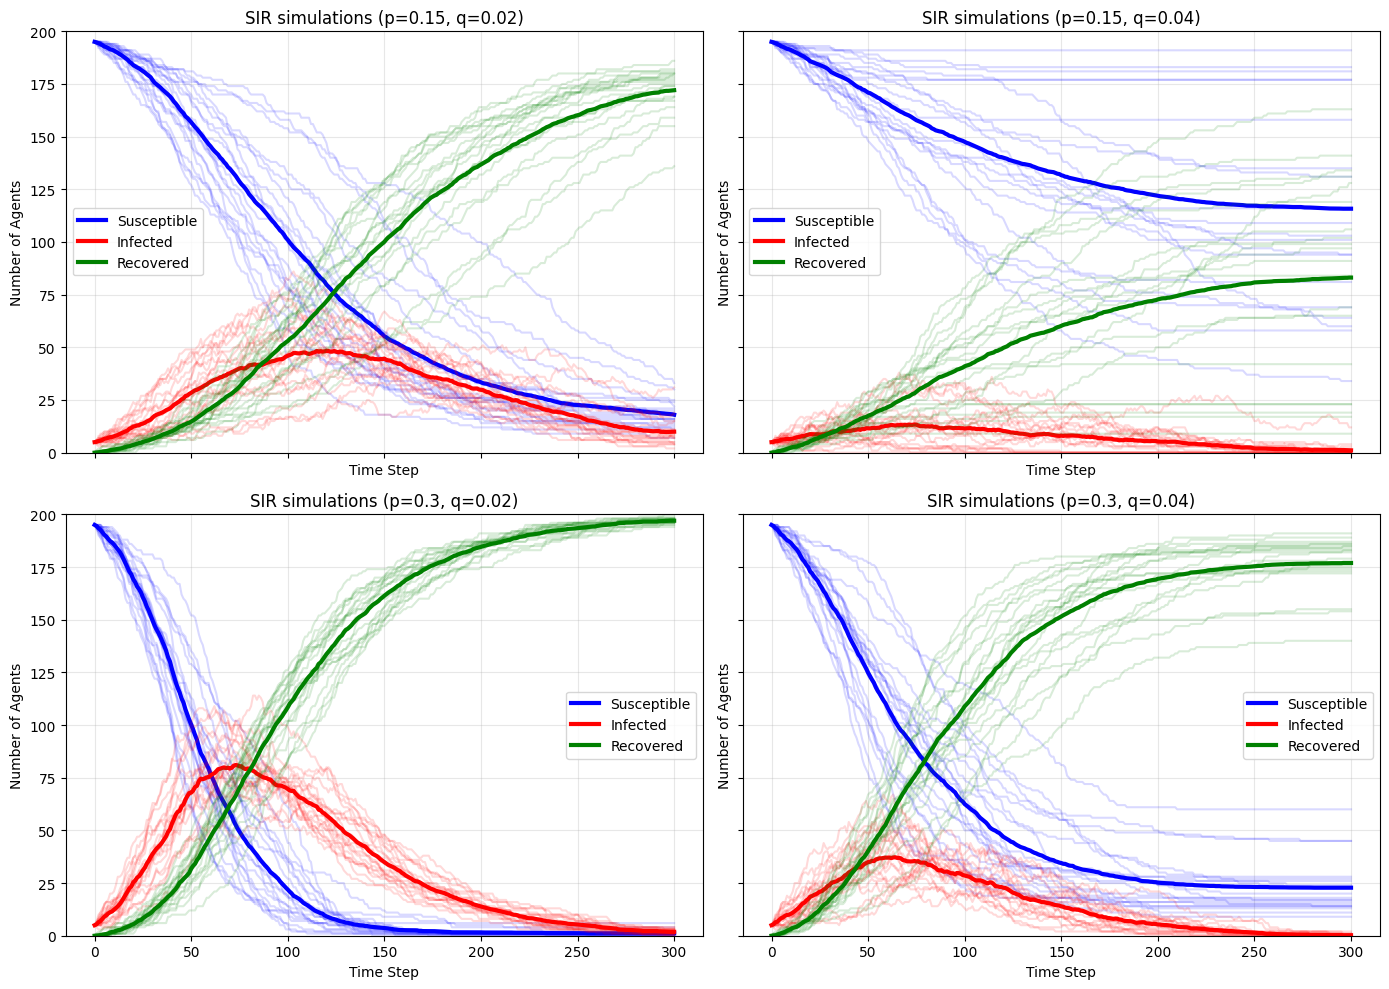

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

for ax, ((p, q), runs) in zip(axes.flat, results.items()):

    avg = runs.mean(axis=0)

    for i in range(3):

        # Plot 20 individual runs
        for run in runs:
            ax.plot(run[:, i], color=colors[i], alpha=0.15)

        # Plot average
        ax.plot(avg[:, i], color=colors[i],
                linewidth=3, label=state_names[i])

    ax.set_title(f'SIR simulations (p={p}, q={q})')
    ax.set_xlabel('Time Step')
    ax.set_ylabel('Number of Agents')
    ax.set_ylim(0, 200)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
summary = []

for (p, q), runs in results.items():

    infected = runs[:, :, 1]  # Infected counts for all 20 runs

    # Peak infected agents and time to peak for each run
    peaks = infected.max(axis=1)
    peak_times = infected.argmax(axis=1)

    # Total ever infected by step 300 (Infected + Recovered)
    total_infected = runs[:, -1, 1] + runs[:, -1, 2]

    # Number of runs where infections die out by step 100
    early_dieout = np.sum(infected[:, 100] == 0)

    # Standard deviation across runs, averaged over all time steps and SIR states
    variability = runs.std(axis=0).mean()

    summary.append({
        'p': p,
        'q': q,
        'Avg Peak Infected': peaks.mean(),
        'Avg Time to Peak': peak_times.mean(),
        'Avg Total Ever Infected': total_infected.mean(),
        'Early Dieout Runs': early_dieout,
        'Mean SIR Std Dev': variability
    })

df_summary = pd.DataFrame(summary)

# Save to CSV
df_summary.to_csv('sir_summary.csv', index=False)

display(df_summary)

,p,q,Avg Peak Infected,Avg Time to Peak,Avg Total Ever Infected,Early Dieout Runs,Mean SIR Std Dev
0,0.15,0.02,58.55,127.05,182.00,0,15.084610
1,0.15,0.04,19.35,70.55,84.20,3,22.276698
2,0.30,0.02,89.10,71.60,198.85,0,7.083295
3,0.30,0.04,45.05,74.65,177.20,0,12.917064


**Interpretation**: 